In [56]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()


Saving Final States Data.xlsx to Final States Data (1).xlsx


In [57]:
import pandas as pd

FILE = "Indian_States_Analysis_Ready_Final.xlsx"

df = pd.read_excel(
    FILE,
    sheet_name="Analysis_Ready_Data"
)

print("Dataset shape:", df.shape)
print(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'Indian_States_Analysis_Ready_Final.xlsx'

In [ ]:
# Clean state names
df["State"] = (
    df["State"]
    .astype(str)
    .str.strip()
)

# Clean year labels
df["Year"] = (
    df["Year"]
    .astype(str)
    .str.strip()
)

print(df["State"].unique())
print(df["Year"].unique())

In [ ]:
duplicates = df[
    df.duplicated(
        subset=["State", "Year"],
        keep=False
    )
]

print("Duplicate State-Year observations:", len(duplicates))

if len(duplicates) > 0:
    print(duplicates.sort_values(["State", "Year"]))

In [ ]:
missing = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
)

print("Missing values:")
print(missing[missing > 0])



In [ ]:
missing_rows = df[
    df.isna().any(axis=1)
].copy()

print(missing_rows.to_string(index=False))

In [ ]:
numeric_columns = [
    "Fiscal Deficit",
    "Revenue Expenditure",
    "Capital Expenditure",
    "Social Sector Expenditure",
    "Per Capita NSDP",
    "GSDP",
    "GSDP(crore)",
    "Outstanding Liabilities",
    "Fiscal Deficit Ratio",
    "Revenue Expenditure Ratio",
    "Capital Expenditure Ratio",
    "Social Sector Expenditure Ratio",
    "Outstanding Liabilities Ratio"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

In [ ]:
# Recalculate ratios

df["Fiscal_Deficit_Ratio_Check"] = (
    df["Fiscal Deficit"] / df["GSDP(crore)"]
)

df["Revenue_Expenditure_Ratio_Check"] = (
    df["Revenue Expenditure"] / df["GSDP(crore)"]
)

df["Capital_Expenditure_Ratio_Check"] = (
    df["Capital Expenditure"] / df["GSDP(crore)"]
)

df["Social_Sector_Ratio_Check"] = (
    df["Social Sector Expenditure"] / df["GSDP(crore)"]
)

df["Liabilities_Ratio_Check"] = (
    df["Outstanding Liabilities"] / df["GSDP(crore)"]
)

In [ ]:
checks = {
    "Fiscal Deficit Ratio":
        "Fiscal_Deficit_Ratio_Check",

    "Revenue Expenditure Ratio":
        "Revenue_Expenditure_Ratio_Check",

    "Capital Expenditure Ratio":
        "Capital_Expenditure_Ratio_Check",

    "Social Sector Expenditure Ratio":
        "Social_Sector_Ratio_Check",

    "Outstanding Liabilities Ratio":
        "Liabilities_Ratio_Check"
}

for original, calculated in checks.items():

    difference = (
        df[original] -
        df[calculated]
    ).abs()

    print(
        original,
        "maximum difference =",
        difference.max()
    )

In [ ]:
gsdp_difference = (
    df["GSDP(crore)"] -
    (df["GSDP"] / 100)
).abs()

print(
    "Maximum GSDP difference:",
    gsdp_difference.max()
)

In [ ]:
from google.colab import files

check_columns = [
    "Fiscal_Deficit_Ratio_Check",
    "Revenue_Expenditure_Ratio_Check",
    "Capital_Expenditure_Ratio_Check",
    "Social_Sector_Ratio_Check",
    "Liabilities_Ratio_Check"
]

# Remove temporary checking columns
df_final = df.drop(
    columns=check_columns,
    errors="ignore"
)

FINAL_FILE = "Indian_States_Final_Analysis_Data.xlsx"

# Save the final 15-column dataset
df_final.to_excel(
    FINAL_FILE,
    index=False
)

In [ ]:
df = pd.read_excel("Final States Data.xlsx")
df["year_start"] = df["Year"].str[:4].astype(int)
df["post_split"] = ((df["State"].isin(["Andhra Pradesh","Telangana"])) & (df["year_start"] >= 2014)).astype(int)

In [ ]:
bad = [("Tripura","2014-15"),("Uttarakhand","2014-15"),("Puducherry","2014-15")]
for s, y in bad:
    m = (df.State == s) & (df.Year == y)
    df.loc[m, ["Outstanding Liabilities","Outstanding Liabilities Ratio"]] = np.nan

In [ ]:
cols = ["Fiscal Deficit Ratio","Revenue Expenditure Ratio","Capital Expenditure Ratio",
        "Social Sector Expenditure Ratio","Outstanding Liabilities Ratio"]

# (a) Winsorise at 1% and 99%
dfw = df.copy()
for c in cols:
    dfw[c] = dfw[c].clip(dfw[c].quantile(.01), dfw[c].quantile(.99))

# (b) Drop special-category states
ne = ["Arunachal Pradesh","Manipur","Meghalaya","Mizoram","Nagaland","Sikkim","Tripura"]
df_no_ne = df[~df.State.isin(ne)]

In [ ]:
df["ln_pcnsdp"] = np.log(df["Per Capita NSDP"])
df["ln_gsdp"]   = np.log(df["GSDP(crore)"])
# Fiscal Deficit Ratio stays as is (can be negative = surplus)

In [ ]:
print(df.groupby("Year")["Per Capita NSDP"].median().pct_change())

In [58]:
g = df.pivot(index="State", columns="Year", values="Per Capita NSDP").pct_change(axis=1)
print(g.median())

Year
2011-12         NaN
2012-13    0.039006
2013-14    0.050732
2014-15    0.048204
2015-16    0.070640
2016-17    0.073629
2017-18    0.058057
2018-19    0.055012
2019-20    0.024134
2020-21   -0.069369
2021-22    0.075180
dtype: float64


In [59]:
liab_cols = ["Outstanding Liabilities", "Outstanding Liabilities Ratio"]

# 2014-15: states whose value looks misaligned
bad_2014_15 = ["Delhi", "West Bengal", "Uttar Pradesh", "Uttarakhand", "Tripura", "Puducherry"]
m = (df.Year == "2014-15") & (df.State.isin(bad_2014_15))
df.loc[m, liab_cols] = np.nan

# Delhi 2017-18 to 2020-21 (about 10x too low)
m = (df.State == "Delhi") & (df.Year.isin(["2017-18", "2018-19", "2019-20", "2020-21"]))
df.loc[m, liab_cols] = np.nan

# Puducherry 2016-17
m = (df.State == "Puducherry") & (df.Year == "2016-17")
df.loc[m, liab_cols] = np.nan

print(df[liab_cols].isna().sum())

Outstanding Liabilities           15
Outstanding Liabilities Ratio    341
dtype: int64


In [60]:
L = df.pivot(index="State", columns="Year", values="Outstanding Liabilities")
nb = (L.shift(1, axis=1) + L.shift(-1, axis=1)) / 2
r = (L / nb).stack()
print(r[(r > 1.6) | (r < 0.6)])

Series([], dtype: float64)


In [61]:
df.to_excel("States_Data_Cleaned.xlsx", index=False)
df["year_start"] = df["Year"].str[:4].astype(int)
df["post_split"] = ((df.State.isin(["Andhra Pradesh","Telangana"])) & (df.year_start >= 2014)).astype(int)
df["ln_pcnsdp"] = np.log(df["Per Capita NSDP"])
df["ln_gsdp"] = np.log(df["GSDP(crore)"])

In [62]:
!pip install linearmodels statsmodels   # only if not installed
import matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from linearmodels.panel import PooledOLS, PanelOLS, RandomEffects
import pandas as pd
import numpy as np

# Corrected the filename from 'Indian_States_Analysis.xlsx' to 'Final States Data.xlsx'
df = pd.read_excel("Final States Data.xlsx")

# the fixes we agreed on (suspect liabilities set to missing)
lc = ["Outstanding Liabilities", "Outstanding Liabilities Ratio"]
df.loc[(df.Year=="2014-15") & df.State.isin(["Delhi","West Bengal","Uttar Pradesh",
        "Uttarakhand","Tripura","Puducherry"]), lc] = np.nan
df.loc[(df.State=="Delhi") & df.Year.isin(["2017-18","2018-19","2019-20","2020-21"]), lc] = np.nan
df.loc[(df.State=="Puducherry") & (df.Year=="2016-17"), lc] = np.nan

# new variables
df["yr"] = df.Year.str[:4].astype(int)
df["post_split"] = (df.State.isin(["Andhra Pradesh","Telangana"]) & (df.yr>=2014)).astype(int)
df["ln_pcnsdp"] = np.log(df["Per Capita NSDP"])
df["ln_gsdp"]   = np.log(df["GSDP(crore)"])
df = df.rename(columns={"Fiscal Deficit Ratio":"fd","Revenue Expenditure Ratio":"rev",
    "Capital Expenditure Ratio":"cap","Social Sector Expenditure Ratio":"soc",
    "Outstanding Liabilities Ratio":"liab"})
df.to_excel("States_Data_Cleaned.xlsx", index=False)

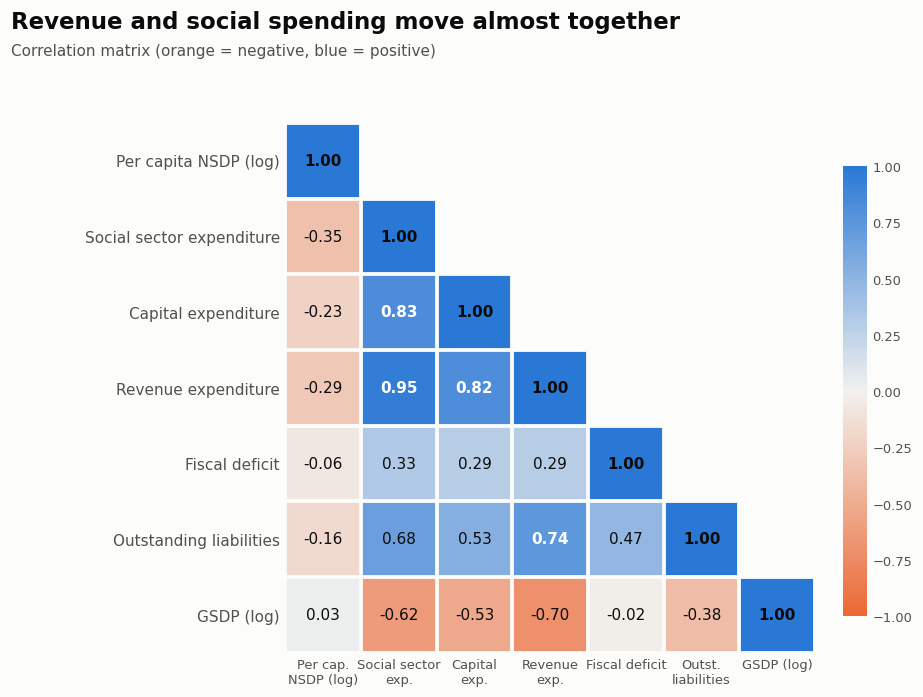

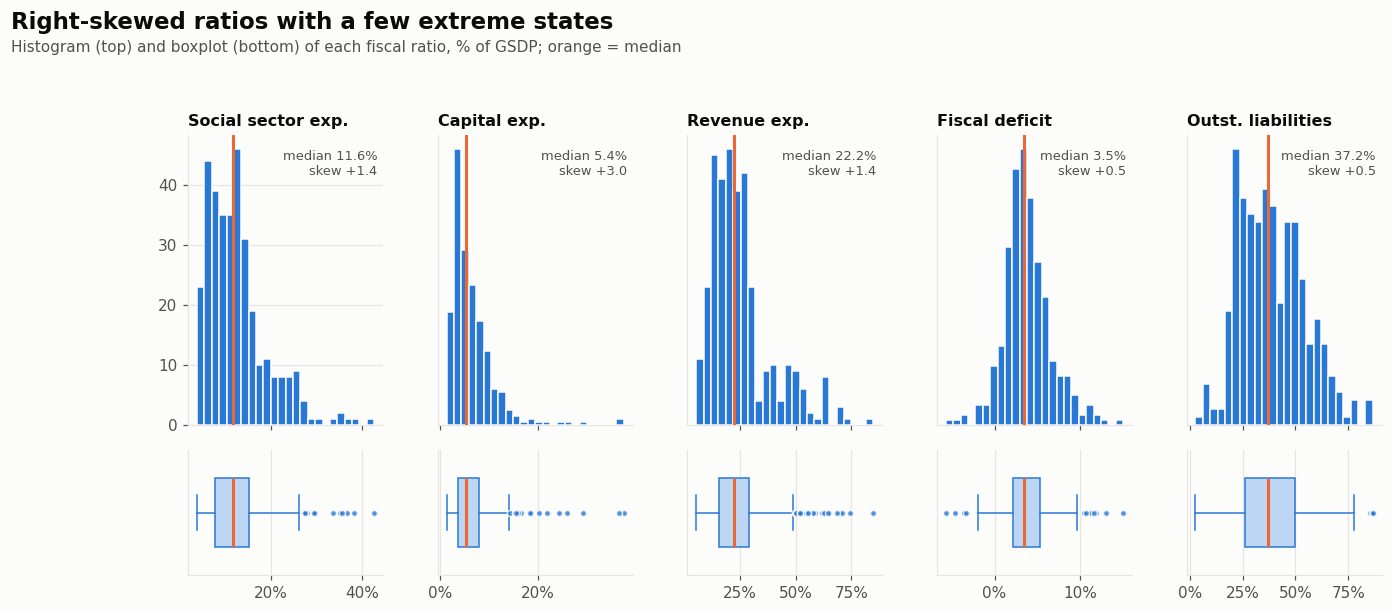

In [63]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, NullFormatter
import warnings; warnings.filterwarnings('ignore')

# ---- palette ----
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"
CAT = [BLUE, ORANGE, AQUA, VIOLET, MAGENTA]

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "legend.frameon": False, "figure.dpi": 110,
})
LAB = {"soc": "Social sector expenditure", "cap": "Capital expenditure", "rev": "Revenue expenditure",
       "fd": "Fiscal deficit", "liab": "Outstanding liabilities", "ln_pcnsdp": "Per capita NSDP (log)",
       "ln_gsdp": "GSDP (log)"}
pct = FuncFormatter(lambda v, _: f"{v:.0f}%")

def headline(fig, title, sub):
    fig.text(0.01, 0.995, title, fontsize=15, fontweight="bold", va="top", color=INK)
    fig.text(0.01, 0.995 - 0.045, sub, fontsize=10, va="top", color=INK2)

# ---------- 1. Correlation heatmap ----------
cols = ["ln_pcnsdp", "soc", "cap", "rev", "fd", "liab", "ln_gsdp"]
c = df[cols].corr(); mask = np.triu(np.ones_like(c, dtype=bool), k=1)
cmap = LinearSegmentedColormap.from_list("div", [ORANGE, "#f2f1ee", BLUE])
fig, ax = plt.subplots(figsize=(8.6, 6.6)); fig.subplots_adjust(top=0.84, left=0.3, right=0.86)
im = ax.imshow(np.ma.array(c.values, mask=mask), cmap=cmap, vmin=-1, vmax=1)
for i in range(len(cols)):
    for j in range(len(cols)):
        if j <= i:
            val = c.values[i, j]
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=10,
                    color="white" if abs(val) > 0.7 and i != j else INK, fontweight="bold" if abs(val) > 0.7 else "normal")
ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
ax.set_xticklabels([LAB[k].replace(" expenditure", "\nexp.").replace("Outstanding ", "Outst.\n").replace("Per capita NSDP (log)", "Per cap.\nNSDP (log)") for k in cols], fontsize=8.5)
ax.set_yticklabels([LAB[k] for k in cols]); ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(np.arange(-.5, len(cols), 1), minor=True); ax.set_yticks(np.arange(-.5, len(cols), 1), minor=True)
ax.grid(which="minor", color=SURFACE, lw=2.5); ax.tick_params(which="minor", length=0)
cax = fig.add_axes([0.89, 0.16, 0.025, 0.62]); cb = fig.colorbar(im, cax=cax); cb.outline.set_visible(False); cb.ax.tick_params(length=0, labelsize=8.5)
headline(fig, "Revenue and social spending move almost together", "Correlation matrix (orange = negative, blue = positive)")
plt.show()

# ---------- 2. Distributions and outliers ----------
vs = ["soc", "cap", "rev", "fd", "liab"]
fig, axes = plt.subplots(2, 5, figsize=(14, 5.8), gridspec_kw={"height_ratios": [3, 1.3]}); fig.subplots_adjust(top=0.80, hspace=0.12, wspace=0.28)
for k, v in enumerate(vs):
    x = df[v].dropna() * 100; a, b = axes[0, k], axes[1, k]
    a.hist(x, bins=24, color=BLUE, edgecolor=SURFACE, linewidth=1, zorder=3); a.axvline(x.median(), color=ORANGE, lw=2, zorder=4)
    a.set_title(LAB[v].replace(" expenditure", " exp.").replace("Outstanding ", "Outst. "), fontsize=10.5)
    a.text(0.97, 0.95, f"median {x.median():.1f}%\nskew {x.skew():+.1f}", transform=a.transAxes, ha="right", va="top", fontsize=8.5, color=INK2)
    a.set_xticklabels([]); a.set_yticks([]) if k else None; a.grid(axis="x", visible=False)
    b.boxplot(x, vert=False, widths=0.55, patch_artist=True, boxprops=dict(facecolor="#bcd6f3", edgecolor=BLUE),
              medianprops=dict(color=ORANGE, lw=2), whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
              flierprops=dict(marker="o", markersize=4, markerfacecolor=BLUE, markeredgecolor=SURFACE, alpha=0.8))
    b.set_yticks([]); b.xaxis.set_major_formatter(pct); b.grid(axis="y", visible=False); b.set_xlim(a.get_xlim())
headline(fig, "Right-skewed ratios with a few extreme states", "Histogram (top) and boxplot (bottom) of each fiscal ratio, % of GSDP; orange = median")
plt.show()

In [64]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = ["soc","cap","rev","fd","liab","ln_gsdp"]
d = df.dropna(subset=["ln_pcnsdp"]+X)
Xv = sm.add_constant(d[X])
print({c: round(variance_inflation_factor(Xv.values,i),1) for i,c in enumerate(Xv.columns) if c!="const"})

{'soc': np.float64(11.7), 'cap': np.float64(3.5), 'rev': np.float64(19.3), 'fd': np.float64(1.4), 'liab': np.float64(3.2), 'ln_gsdp': np.float64(2.4)}


In [65]:
def fit_models(X, data):
    p = data.dropna(subset=["ln_pcnsdp"]+X).set_index(["State","yr"])
    yd = pd.get_dummies(p.index.get_level_values("yr"), prefix="y", drop_first=True, dtype=float)
    yd.index = p.index
    x = sm.add_constant(pd.concat([p[X], yd], axis=1)); y = p["ln_pcnsdp"]
    pooled = PooledOLS(y, x).fit(cov_type="clustered", cluster_entity=True)
    fe = PanelOLS(y, x, entity_effects=True, drop_absorbed=True).fit(cov_type="clustered", cluster_entity=True)
    re = RandomEffects(y, x).fit(cov_type="clustered", cluster_entity=True)
    return pooled, fe, re, x, y

specA = ["soc","cap","rev","fd","liab","ln_gsdp"]   # your proposal
specB = ["soc","cap","rev","fd","liab"]              # without GSDP
specC = ["soc","cap","fd","liab"]                    # without revenue exp (collinearity)

In [66]:
# ===== Animated EDA charts (plotly) =====
import numpy as np, pandas as pd, plotly.graph_objects as go, plotly.express as px

INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, AQUA, VIOLET, MAGENTA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e87ba4", "#8a8984"
years = sorted(df.Year.unique())

def style(fig, title, sub, height=560):
    fig.update_layout(template="simple_white", paper_bgcolor=SURFACE, plot_bgcolor=SURFACE, height=height,
        font=dict(family="Arial", color=INK2, size=12),
        title=dict(text=f"<b>{title}</b><br><span style='font-size:12px;color:{INK2}'>{sub}</span>", x=0.01, y=0.96),
        margin=dict(t=95, l=70, r=40, b=70))
    fig.update_xaxes(gridcolor=GRID, linecolor=GRID); fig.update_yaxes(gridcolor=GRID, linecolor=GRID)
    for m in fig.layout.updatemenus or []:                      # slower, smoother playback
        for b in m.buttons:
            if b.label.lower().startswith("play") or b.label == "▶":
                b.args[1]["frame"] = dict(duration=900, redraw=True); b.args[1]["transition"] = dict(duration=500)
    return fig

# ---------- 1. Animated trend: lines draw year by year ----------
sel = ["Goa", "Delhi", "Gujarat", "Tamil Nadu", "Bihar"]; cols = [BLUE, ORANGE, AQUA, VIOLET, MAGENTA]
piv = df.pivot(index="Year", columns="State", values="Per Capita NSDP")[sel] / 1000
med = df.groupby("Year")["Per Capita NSDP"].median() / 1000

def traces(k):
    t = [go.Scatter(x=years[:k], y=med.values[:k], name="All-state median", mode="lines",
                    line=dict(color=MUTED, dash="dash", width=2))]
    for s, c in zip(sel, cols):
        t.append(go.Scatter(x=years[:k], y=piv[s].values[:k], name=s, mode="lines+markers",
                            line=dict(color=c, width=3), marker=dict(size=7, line=dict(color=SURFACE, width=1.5))))
    return t

fig1 = go.Figure(data=traces(1), frames=[go.Frame(data=traces(k), name=years[k-1]) for k in range(1, len(years)+1)])
fig1.update_layout(
    xaxis=dict(type="category", range=[-0.3, len(years)-0.7], categoryorder="array", categoryarray=years, title=""),
    yaxis=dict(range=[0, 340], title="Per capita NSDP (₹ '000, constant prices)"),
    updatemenus=[dict(type="buttons", x=0.01, y=-0.18, direction="left", buttons=[
        dict(label="▶ Play", method="animate", args=[None, dict(frame=dict(duration=800, redraw=True), transition=dict(duration=400), fromcurrent=True)]),
        dict(label="⏸ Pause", method="animate", args=[[None], dict(frame=dict(duration=0), mode="immediate")])])],
    sliders=[dict(x=0.12, len=0.85, y=-0.12, currentvalue=dict(prefix="Year: "),
                  steps=[dict(label=y, method="animate", args=[[y], dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))]) for y in years])])
style(fig1, "Incomes diverge sharply across states", "Per capita NSDP, selected states vs. all-state median")
fig1.show(); fig1.write_html("anim_1_trend.html", auto_play=False)

# ---------- 2. Animated bubble scatter: spending vs income ----------
def bubble(var, label, xmax):
    d = df.dropna(subset=[var]).sort_values("yr").copy()
    d["tag"] = np.where(d.State.isin(["Goa", "Delhi", "Bihar", "Gujarat", "Arunachal Pradesh", "Manipur"]), d.State, "")
    fig = px.scatter(d, x=d[var]*100, y="Per Capita NSDP", size="GSDP(crore)", hover_name="State", text="tag",
                     animation_frame="Year", log_y=True, size_max=45, range_x=[0, xmax], range_y=[15000, 350000],
                     opacity=0.65, color_discrete_sequence=[BLUE],
                     labels={"x": f"{label} (% of GSDP)", "Per Capita NSDP": "Per capita NSDP (₹, log scale)"})
    fig.update_traces(marker=dict(line=dict(color=SURFACE, width=1.5)), textposition="top center", textfont=dict(color=INK, size=11))
    fig.update_layout(showlegend=False)
    style(fig, f"States over time: {label.lower()} vs. income", "Each bubble is a state; bubble size = GSDP. Hover for the state name.")
    fig.update_yaxes(tickvals=[20000, 50000, 100000, 200000, 300000], ticktext=["20k", "50k", "100k", "200k", "300k"])
    return fig

fig2 = bubble("soc", "Social sector spending", 50); fig2.show(); fig2.write_html("anim_2_bubble_social.html", auto_play=False)
fig2b = bubble("cap", "Capital spending", 40);       fig2b.show(); fig2b.write_html("anim_2_bubble_capital.html", auto_play=False)

# ---------- 3. Animated bar race: top 15 states by spending ratio ----------
def bar_race(var, label, color, top=15):
    frames, first = [], None
    for y in years:
        s = df[df.Year == y].dropna(subset=[var]).nlargest(top, var).sort_values(var)
        bar = go.Bar(x=s[var]*100, y=s.State, orientation="h", marker=dict(color=color),
                     text=[f"{v*100:.1f}%" for v in s[var]], textposition="outside", cliponaxis=False)
        frames.append(go.Frame(data=[bar], name=y, layout=go.Layout(yaxis=dict(categoryorder="array", categoryarray=list(s.State)))))
        if first is None: first = (bar, list(s.State))
    fig = go.Figure(data=[first[0]], frames=frames)
    fig.update_layout(
        xaxis=dict(range=[0, df[var].max()*100*1.2], ticksuffix="%", title=f"{label.capitalize()} (% of GSDP)"),
        yaxis=dict(categoryorder="array", categoryarray=first[1]),
        updatemenus=[dict(type="buttons", x=0.01, y=-0.14, direction="left", buttons=[
            dict(label="▶ Play", method="animate", args=[None, dict(frame=dict(duration=1000, redraw=True), transition=dict(duration=500), fromcurrent=True)]),
            dict(label="⏸ Pause", method="animate", args=[[None], dict(frame=dict(duration=0), mode="immediate")])])],
        sliders=[dict(x=0.12, len=0.85, y=-0.08, currentvalue=dict(prefix="Year: "),
                      steps=[dict(label=y, method="animate", args=[[y], dict(mode="immediate", frame=dict(duration=0, redraw=True), transition=dict(duration=0))]) for y in years])])
    style(fig, f"Top {top} states by {label.lower()}", "Share of GSDP, ranked each year", height=620)
    return fig

fig3  = bar_race("soc", "social sector spending", BLUE); fig3.show();  fig3.write_html("anim_3_race_social.html", auto_play=False)
fig3b = bar_race("cap", "capital spending", AQUA);        fig3b.show(); fig3b.write_html("anim_3_race_capital.html", auto_play=False)

In [67]:
"""Panel estimators in plain numpy/scipy: pooled OLS, FE (within), RE (Swamy-Arora GLS),
entity-clustered SEs, F-test for effects, Breusch-Pagan LM, Hausman (classical) and Mundlak (robust)."""
import numpy as np, pandas as pd
from scipy import stats

Y = "ln_pcnsdp"


def prep(data, X, y=Y):
    """Estimation sample + year dummies (first year dropped). Returns frame with State, yr, y, X, year dummies."""
    p = data.dropna(subset=[y] + list(X)).copy()
    yd = pd.get_dummies(p["yr"], prefix="y", drop_first=True, dtype=float)
    p = pd.concat([p[["State", "yr", y] + list(X)], yd], axis=1)
    return p, list(X) + list(yd.columns)


def _cluster_cov(Xm, e, g, XtXi, adj):
    k = Xm.shape[1]
    meat = np.zeros((k, k))
    for gi in np.unique(g):
        s = Xm[g == gi].T @ e[g == gi]
        meat += np.outer(s, s)
    return adj * XtXi @ meat @ XtXi


In [68]:
def _fit_ols(Xm, y, g, names, adj_kind="cr1"):
    n, k = Xm.shape
    G = len(np.unique(g))
    XtXi = np.linalg.inv(Xm.T @ Xm)
    b = XtXi @ Xm.T @ y
    e = y - Xm @ b
    adj = G / (G - 1) * ((n - 1) / (n - k) if adj_kind == "cr1" else 1.0)
    V = _cluster_cov(Xm, e, g, XtXi, adj)
    return dict(b=pd.Series(b, names), V=pd.DataFrame(V, names, names), e=e, XtXi=XtXi,
                n=n, G=G, k=k, ssr=float(e @ e))


def _summ(res, df_t, rsq=None):
    se = pd.Series(np.sqrt(np.diag(res["V"])), res["b"].index)
    t = res["b"] / se
    p = pd.Series(2 * stats.t.sf(np.abs(t), df_t), res["b"].index)
    return pd.DataFrame({"coef": res["b"], "se": se, "t": t, "p": p})


def pooled(p, xn, y=Y):
    g = p["State"].values
    Xm = np.column_stack([np.ones(len(p)), p[xn].values])
    r = _fit_ols(Xm, p[y].values, g, ["const"] + xn)
    r["table"] = _summ(r, r["G"] - 1)
    ybar = p[y].mean(); r["r2"] = 1 - r["ssr"] / ((p[y] - ybar) ** 2).sum()
    r["resid"] = pd.Series(r["e"], p.index)
    return r

In [69]:
def _demean(df_, g):
    return df_ - df_.groupby(g).transform("mean")


def fe(p, xn, y=Y):
    g = p["State"].values
    Xd = _demean(p[xn], p["State"]).values
    yd = _demean(p[y], p["State"]).values
    r = _fit_ols(Xd, yd, g, xn, adj_kind="g_only")
    n, G, k = r["n"], r["G"], len(xn)
    r["dof"] = n - G - k
    r["sig2e"] = r["ssr"] / r["dof"]
    r["Vc"] = pd.DataFrame(r["sig2e"] * r["XtXi"], xn, xn)  # classical
    r["table"] = _summ(r, G - 1)
    r["r2_within"] = 1 - r["ssr"] / (yd @ yd)
    return r

def re(p, xn, fer, y=Y):
    g = p["State"]
    n, G = len(p), g.nunique()
    T = g.map(g.value_counts()).values
    # between regression -> sigma_u^2 (Swamy-Arora)
    pm = p[[y] + xn].groupby(g).mean()
    Xb = np.column_stack([np.ones(G), pm[xn].values])
    bb = np.linalg.lstsq(Xb, pm[y].values, rcond=None)[0]
    s2b = ((pm[y].values - Xb @ bb) ** 2).sum() / (G - Xb.shape[1])
    Th = G / (1 / g.value_counts()).sum()
    s2e = fer["sig2e"]
    s2u = max(0.0, s2b - s2e / Th)
    theta = 1 - np.sqrt(s2e / (s2e + T * s2u))
    Xfull = np.column_stack([np.ones(n), p[xn].values])
    ym = p.groupby("State")[y].transform("mean").values
    xm = np.column_stack([np.ones(n), p[xn].values])
    xm = pd.DataFrame(xm).groupby(g.values).transform("mean").values
    Xs = Xfull - theta[:, None] * xm
    ys = p[y].values - theta * ym
    r = _fit_ols(Xs, ys, g.values, ["const"] + xn)
    r["Vc"] = pd.DataFrame(s2e * r["XtXi"], ["const"] + xn, ["const"] + xn)
    r["table"] = _summ(r, G - 1)
    r["sig2e"], r["sig2u"], r["theta_mean"] = s2e, s2u, theta.mean()
    r["rho"] = s2u / (s2u + s2e)
    return r

In [70]:
def f_effects(pr, fr):
    n, G, k = fr["n"], fr["G"], fr["k"]
    F = ((pr["ssr"] - fr["ssr"]) / (G - 1)) / (fr["ssr"] / (n - G - k))
    return F, G - 1, n - G - k, stats.f.sf(F, G - 1, n - G - k)


def bp_lm(pr, p):
    e = pr["resid"]; g = e.groupby(p["State"])
    A = (g.sum() ** 2).sum() - (e ** 2).sum()
    T = g.size()
    LM = (A / ((e ** 2).sum() / len(e))) ** 2 / (2 * (T * (T - 1)).sum())
    return float(LM), float(stats.chi2.sf(LM, 1))


def hausman(fr, rr, names):
    d = fr["b"][names] - rr["b"][names]
    Vd = fr["Vc"].loc[names, names] - rr["Vc"].loc[names, names]
    ev = np.linalg.eigvalsh(Vd.values)
    H = float(d.values @ np.linalg.inv(Vd.values) @ d.values)
    return H, len(names), float(stats.chi2.sf(H, len(names))) if H >= 0 else np.nan, ev.min()


In [71]:
def mundlak(p, xn, yn, xcore, y=Y):
    """Pooled OLS + entity means of the time-varying core regressors; cluster-robust joint Wald on the means."""
    mm = p[xcore].groupby(p["State"]).transform("mean"); mm.columns = ["m_" + c for c in xcore]
    Xm = np.column_stack([np.ones(len(p)), p[xn].values, mm.values])
    names = ["const"] + xn + list(mm.columns)
    r = _fit_ols(Xm, p[y].values, p["State"].values, names)
    idx = list(mm.columns)
    b = r["b"][idx].values; V = r["V"].loc[idx, idx].values
    W = float(b @ np.linalg.inv(V) @ b); q = len(idx)
    return W, q, float(stats.chi2.sf(W, q)), float(stats.f.sf(W / q, q, r["G"] - 1))


def run_all(data, X):
    p, xn = prep(data, X)
    pr = pooled(p, xn); fr = fe(p, xn); rr = re(p, xn, fr)
    out = dict(p=p, xn=xn, pooled=pr, fe=fr, re=rr, X=list(X))
    out["F"] = f_effects(pr, fr)
    out["LM"] = bp_lm(pr, p)
    out["H_all"] = hausman(fr, rr, xn)
    out["H_core"] = hausman(fr, rr, list(X))
    out["mundlak"] = mundlak(p, xn, xn, list(X))
    return out

# ---- robustness helpers ----
RATIOS=["fd","rev","cap","soc","liab"]
NE7=["Arunachal Pradesh","Manipur","Meghalaya","Mizoram","Nagaland","Sikkim","Tripura"]
SPECIAL11=NE7+["Assam","Himachal Pradesh","Jammu & Kashmir","Uttarakhand"]
def variants(df, X):
    d=df.sort_values(["State","yr"]).copy()
    w=d.copy()
    for c in RATIOS: w[c]=w[c].clip(w[c].quantile(.01), w[c].quantile(.99))
    lag=d.copy()
    for c in X: lag[c]=lag.groupby("State")[c].shift(1)
    return {"Baseline":(d,X),
            "Winsorised (1%/99%)":(w,X),
            "No NE special-category (7)":(d[~d.State.isin(NE7)],X),
            "No special-category (11)":(d[~d.State.isin(SPECIAL11)],X),
            "+ post_split dummy":(d,X+["post_split"]),
            "Lagged regressors (t-1)":(lag,X),
            "Excluding 2020-21":(d[d.yr!=2020],X)}
def robustness(df, X, model="fe"):
    rows=[]
    for name,(dd,XX) in variants(df,X).items():
        p,xn=prep(dd,XX); fr=fe(p,xn)
        r = fr if model=="fe" else re(p,xn,fr)
        t=r["table"]
        for v in XX:
            rows.append(dict(variant=name,var=v,coef=t.loc[v,"coef"],se=t.loc[v,"se"],p=t.loc[v,"p"],n=r["n"],G=r["G"]))
    return pd.DataFrame(rows)


In [72]:
# ===== TASK 3: Pooled OLS, Fixed effects, Random effects for specs A, B, C =====
# Dependent variable: ln(per capita NSDP). Year dummies in all models. SEs clustered by state (small-sample corrected).
# Ratios are fractions (0.01 = 1 percentage point of GSDP), so a coefficient of -0.88 means -0.0088 log points per 1 pp.
SPECS = {"A (with ln GSDP)": ["soc","cap","rev","fd","liab","ln_gsdp"],
         "B (without ln GSDP)": ["soc","cap","rev","fd","liab"],
         "C (without revenue exp.)": ["soc","cap","fd","liab"]}
NICE = {"soc":"Social sector exp.","cap":"Capital exp.","rev":"Revenue exp.","fd":"Fiscal deficit","liab":"Outstanding liabilities","ln_gsdp":"ln GSDP"}

def stars(p): return "***" if p<.01 else "**" if p<.05 else "*" if p<.10 else ""

res = {k: run_all(df, X) for k, X in SPECS.items()}

def coef_table(o):
    rows = {}
    for v in o["X"]:
        rows[NICE[v]] = {m: f'{o[m]["table"].loc[v,"coef"]:.3f}{stars(o[m]["table"].loc[v,"p"])} ({o[m]["table"].loc[v,"se"]:.3f})'
                         for m in ["pooled","fe","re"]}
    t = pd.DataFrame(rows).T; t.columns = ["Pooled OLS","Fixed effects","Random effects"]
    t.loc["Observations"] = [o["pooled"]["n"], o["fe"]["n"], o["re"]["n"]]
    t.loc["States"] = [o["fe"]["G"]]*3
    t.loc["R-squared (pooled) / within (FE)"] = [f'{o["pooled"]["r2"]:.3f}', f'{o["fe"]["r2_within"]:.3f}', ""]
    return t

tab3 = {k: coef_table(o) for k, o in res.items()}
for k, t in tab3.items():
    print(f"\n=== Spec {k}: coef (cluster-robust SE); * p<.10  ** p<.05  *** p<.01 ===")
    print(t.to_string())


=== Spec A (with ln GSDP): coef (cluster-robust SE); * p<.10  ** p<.05  *** p<.01 ===
                                          Pooled OLS     Fixed effects    Random effects
Social sector exp.                -10.426*** (3.050)     0.034 (0.189)     0.007 (0.219)
Capital exp.                           3.802 (2.277)     0.137 (0.106)     0.140 (0.123)
Revenue exp.                           0.492 (1.419)    -0.163 (0.106)   -0.251* (0.138)
Fiscal deficit                         2.171 (1.428)    -0.000 (0.046)     0.036 (0.077)
Outstanding liabilities               -0.814 (0.555)     0.038 (0.055)    -0.002 (0.067)
ln GSDP                            -0.244*** (0.067)  1.031*** (0.041)  0.865*** (0.044)
Observations                                     326               326               326
States                                            31                31                31
R-squared (pooled) / within (FE)               0.521             0.987                  

=== Spec B (without ln

In [73]:
# ===== TASK 4: F-test, Breusch-Pagan LM, Hausman -> choose the model =====
def sci(p): return f"{p:.3g}"
rows = []
for k, o in res.items():
    F, d1, d2, pF = o["F"]; LM, pLM = o["LM"]; H, hdf, pH, _ = o["H_core"]; W, q, pW, pWF = o["mundlak"]
    # decision: F decides FE vs pooled; LM decides RE vs pooled; Hausman decides FE vs RE
    hs = "FE" if pH < 0.05 else "RE"
    rows.append({"Spec": k,
                 "F (FE vs pooled)": f"{F:.1f} (df {d1},{d2}), p={sci(pF)}",
                 "BP-LM (RE vs pooled)": f"{LM:.1f}, p={sci(pLM)}",
                 "Hausman (FE vs RE)": f"{H:.2f} (df {hdf}), p={pH:.3f}",
                 "Robust Hausman / Mundlak": f"chi2({q})={W:.2f}, p={pW:.3f}",
                 "Hausman says": hs})
tab4 = pd.DataFrame(rows).set_index("Spec")
print(tab4.T.to_string())
print("\nReading: F and BP-LM both reject 'no state effects' in every spec -> pooled OLS is ruled out.")
print("Hausman (classical, on the fiscal regressors) chooses between FE and RE; the Mundlak test is the cluster-robust version.")

Spec                             A (with ln GSDP)            B (without ln GSDP)     C (without revenue exp.)
F (FE vs pooled)          4434.9 (df 30,279), p=0  745.8 (df 30,280), p=1.7e-248  744.6 (df 30,281), p=4e-249
BP-LM (RE vs pooled)           944.4, p=2.17e-207            1253.0, p=1.87e-274          1407.6, p=4.69e-308
Hausman (FE vs RE)         364.93 (df 6), p=0.000           7.94 (df 5), p=0.159         4.63 (df 4), p=0.327
Robust Hausman / Mundlak   chi2(6)=30.28, p=0.000         chi2(5)=12.49, p=0.029        chi2(4)=4.58, p=0.333
Hausman says                                   FE                             RE                           RE

Reading: F and BP-LM both reject 'no state effects' in every spec -> pooled OLS is ruled out.
Hausman (classical, on the fiscal regressors) chooses between FE and RE; the Mundlak test is the cluster-robust version.


In [74]:
# ===== TASK 5: Robustness (fixed effects; RE results are saved to the Excel file) =====
rob_fe, rob_re = {}, {}
for k, X in SPECS.items():
    rob_fe[k] = robustness(df, X, "fe")
    rob_re[k] = robustness(df, X, "re")
    r = rob_fe[k].copy()
    r["cell"] = r.apply(lambda x: f"{x['coef']:.3f}{stars(x['p'])}", axis=1)
    order = list(variants(df, X).keys())
    t = r.pivot(index="variant", columns="var", values="cell").reindex(order)
    t = t[[c for c in X + ["post_split"] if c in t.columns]].join(r.groupby("variant")["n"].first())
    t = t.rename(columns=NICE)
    print(f"\n=== Robustness, fixed effects, Spec {k} ===")
    print(t.fillna("").to_string())


=== Robustness, fixed effects, Spec A (with ln GSDP) ===
                           Social sector exp. Capital exp. Revenue exp. Fiscal deficit Outstanding liabilities   ln GSDP post_split    n
variant                                                                                                                                 
Baseline                                0.034        0.137       -0.163         -0.000                   0.038  1.031***             326
Winsorised (1%/99%)                     0.015        0.171       -0.140          0.007                   0.029  1.034***             326
No NE special-category (7)              0.050        0.061     -0.384**          0.161                   0.082  1.010***             250
No special-category (11)                0.068       -0.021    -0.585***          0.124                  0.171*  1.001***             207
+ post_split dummy                      0.007        0.152       -0.135         -0.009                   0.044  1.034***

In [75]:
# ===== Save everything to one Excel file =====
with pd.ExcelWriter("Tasks_3_to_5_Results.xlsx") as xw:
    for k, t in tab3.items(): t.to_excel(xw, sheet_name=("T3 "+k[:1]))
    tab4.T.to_excel(xw, sheet_name="T4 Tests")
    for k in SPECS:
        rob_fe[k].to_excel(xw, sheet_name=("T5 FE "+k[:1]), index=False)
        rob_re[k].to_excel(xw, sheet_name=("T5 RE "+k[:1]), index=False)
print("saved Tasks_3_to_5_Results.xlsx")
# from google.colab import files; files.download("Tasks_3_to_5_Results.xlsx")

saved Tasks_3_to_5_Results.xlsx


In [76]:
# ===== TASK: Descriptive statistics (run any time after the cleaning cell) =====
vars_ = ["ln_pcnsdp","Per Capita NSDP","soc","cap","rev","fd","liab","ln_gsdp"]
desc = df[vars_].describe().T[["count","mean","std","min","25%","50%","75%","max"]].round(3)
desc.index = ["ln Per capita NSDP","Per capita NSDP (Rs)","Social sector exp./GSDP","Capital exp./GSDP",
              "Revenue exp./GSDP","Fiscal deficit/GSDP","Outstanding liabilities/GSDP","ln GSDP"]
print(desc.to_string())

state_avg = (df.groupby("State")[["Per Capita NSDP","soc","cap","rev","fd","liab"]].mean()
               .rename(columns={"Per Capita NSDP":"Per capita NSDP","soc":"Social","cap":"Capital","rev":"Revenue",
                                "fd":"Fiscal deficit","liab":"Liabilities"})
               .sort_values("Per capita NSDP", ascending=False).round(3))
print("\nState-wise averages (2011-12 to 2021-22), ratios are fractions of GSDP")
print(state_avg.to_string())

                              count        mean        std        min        25%        50%         75%         max
ln Per capita NSDP            341.0      11.380      0.550      9.987     10.979     11.395      11.781      12.657
Per capita NSDP (Rs)          341.0  101644.460  58428.342  21750.000  58619.000  88915.000  130741.000  313973.000
Social sector exp./GSDP       338.0       0.126      0.066      0.037      0.076      0.116       0.151       0.426
Capital exp./GSDP             338.0       0.065      0.046      0.013      0.037      0.054       0.080       0.377
Revenue exp./GSDP             338.0       0.255      0.140      0.052      0.157      0.222       0.290       0.850
Fiscal deficit/GSDP           338.0       0.038      0.028     -0.057      0.021      0.035       0.053       0.150
Outstanding liabilities/GSDP  326.0       0.391      0.156      0.027      0.264      0.372       0.498       0.866
ln GSDP                       341.0      12.038      1.537      8.890   

In [77]:
# ===== TASK: Summary coefficient table + hypothesis table (H1-H5). Needs the Task 3-5 cells to have run. =====
MAIN  = "B (without ln GSDP)"   # the report's baseline model. Alternatives: "B (without ln GSDP)", "C (without revenue exp.)"
MODEL = "fe"                 # "fe" or "re": the model you report as preferred (see the Task 4 table)
ALPHA = 0.05

o = res[MAIN]
print(f"=== Summary table, spec {MAIN} (coef, cluster-robust SE in brackets; * p<.10 ** p<.05 *** p<.01) ===")
print(tab3[MAIN].to_string())

# H1, H2: one-sided (positive association). H3-H5: two-sided (any significant relationship).
HYP = [("H1","soc","Social sector exp. -> higher NSDP (+)","pos"),
       ("H2","cap","Capital exp. -> higher NSDP (+)","pos"),
       ("H3","rev","Revenue exp. significant","two"),
       ("H4","fd","Fiscal deficit significant","two"),
       ("H5","liab","Liabilities significant","two")]

def verdict(coef, p2, kind):
    if kind == "pos":
        p = p2/2 if coef > 0 else 1 - p2/2
        return p, ("Supported" if (coef > 0 and p < ALPHA) else "Not supported")
    return p2, ("Supported" if p2 < ALPHA else "Not supported")

rob = (rob_fe if MODEL == "fe" else rob_re)[MAIN]
rows = []
for h, v, text, kind in HYP:
    if v not in o["X"]:
        rows.append({"Hypothesis": h, "Statement": text, "Coef": "", "p (test)": "", "Result": "Not testable in this spec",
                     "Robustness (checks supported / 6)": ""}); continue
    t = o[MODEL]["table"].loc[v]
    p, res_ = verdict(t["coef"], t["p"], kind)
    rr = rob[(rob["var"] == v) & (rob["variant"] != "Baseline")]
    n_sup = sum(verdict(c, pp, kind)[1] == "Supported" for c, pp in zip(rr["coef"], rr["p"]))
    rows.append({"Hypothesis": h, "Statement": text, "Coef": f'{t["coef"]:.3f}{stars(t["p"])}', "p (test)": f"{p:.3f}",
                 "Result": res_, "Robustness (checks supported / 6)": f"{n_sup} / {len(rr)}"})
tab6 = pd.DataFrame(rows).set_index("Hypothesis")
print(f"\n=== Hypothesis table: {MODEL.upper()} model, spec {MAIN}, {int(ALPHA*100)}% level ===")
print(tab6.to_string())
print("\nNote: the robustness count uses the six variants (winsorised, no 7 NE states, no 11 special-category states,",
      "post_split dummy, lagged regressors, no 2020-21).")

with pd.ExcelWriter("Task6_Tables.xlsx") as xw:
    tab3[MAIN].to_excel(xw, sheet_name="Summary table"); tab6.to_excel(xw, sheet_name="Hypotheses")

=== Summary table, spec B (without ln GSDP) (coef, cluster-robust SE in brackets; * p<.10 ** p<.05 *** p<.01) ===
                                          Pooled OLS     Fixed effects    Random effects
Social sector exp.                -11.274*** (3.711)     0.037 (0.445)     0.013 (0.456)
Capital exp.                           2.374 (2.041)     0.097 (0.423)     0.103 (0.435)
Revenue exp.                         3.709** (1.716)  -0.884** (0.361)  -0.878** (0.370)
Fiscal deficit                         1.287 (1.402)     0.246 (0.331)     0.250 (0.340)
Outstanding liabilities              -1.188* (0.678)    -0.201 (0.164)    -0.204 (0.166)
Observations                                     326               326               326
States                                            31                31                31
R-squared (pooled) / within (FE)               0.342             0.897                  

=== Hypothesis table: FE model, spec B (without ln GSDP), 5% level ===
             

In [78]:
def hyp_table(spec, model="fe", alpha=0.05):
    o, rob = res[spec], (rob_fe if model == "fe" else rob_re)[spec]
    out = {}
    for h, v, text, kind in HYP:                      # HYP and verdict() come from the Task 6 cell
        if v not in o["X"]: out[h] = ("n/a", "", "not testable", ""); continue
        t = o[model]["table"].loc[v]; p, r = verdict(t["coef"], t["p"], kind)
        rr = rob[(rob["var"] == v) & (rob["variant"] != "Baseline")]
        n_sup = sum(verdict(c, pp, kind)[1] == "Supported" for c, pp in zip(rr["coef"], rr["p"]))
        out[h] = (f'{t["coef"]:.3f}{stars(t["p"])}', f"{p:.3f}", r, f"{n_sup}/{len(rr)}")
    return pd.DataFrame(out, index=["Coef", "p (test)", "Result", "Robust checks"]).T

for spec in SPECS:
    for model in ["fe", "re"]:
        print(f"\n=== {spec} | {model.upper()} ==="); print(hyp_table(spec, model).to_string())



=== A (with ln GSDP) | FE ===
      Coef p (test)         Result Robust checks
H1   0.034    0.430  Not supported           0/6
H2   0.137    0.102  Not supported           0/6
H3  -0.163    0.135  Not supported           2/6
H4  -0.000    0.998  Not supported           1/6
H5   0.038    0.486  Not supported           0/6

=== A (with ln GSDP) | RE ===
       Coef p (test)         Result Robust checks
H1    0.007    0.487  Not supported           0/6
H2    0.140    0.132  Not supported           0/6
H3  -0.251*    0.081  Not supported           2/6
H4    0.036    0.647  Not supported           1/6
H5   -0.002    0.982  Not supported           0/6

=== B (without ln GSDP) | FE ===
        Coef p (test)         Result Robust checks
H1     0.037    0.468  Not supported           0/6
H2     0.097    0.410  Not supported           0/6
H3  -0.884**    0.020      Supported           6/6
H4     0.246    0.464  Not supported           1/6
H5    -0.201    0.231  Not supported           0/6

===

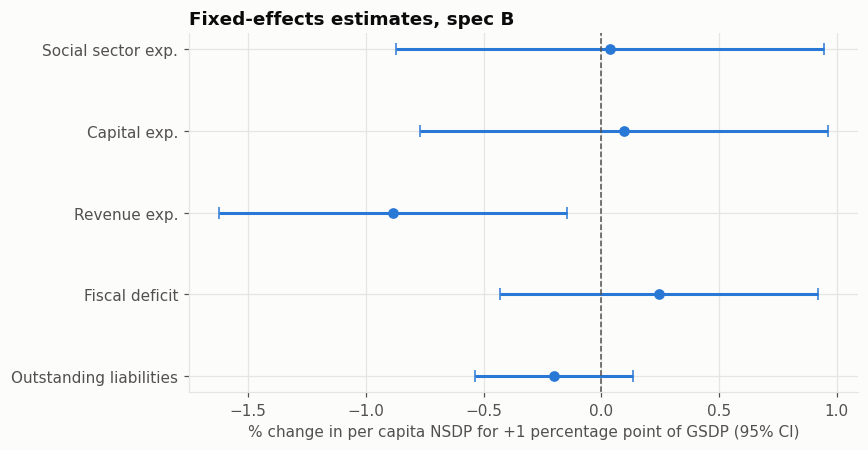

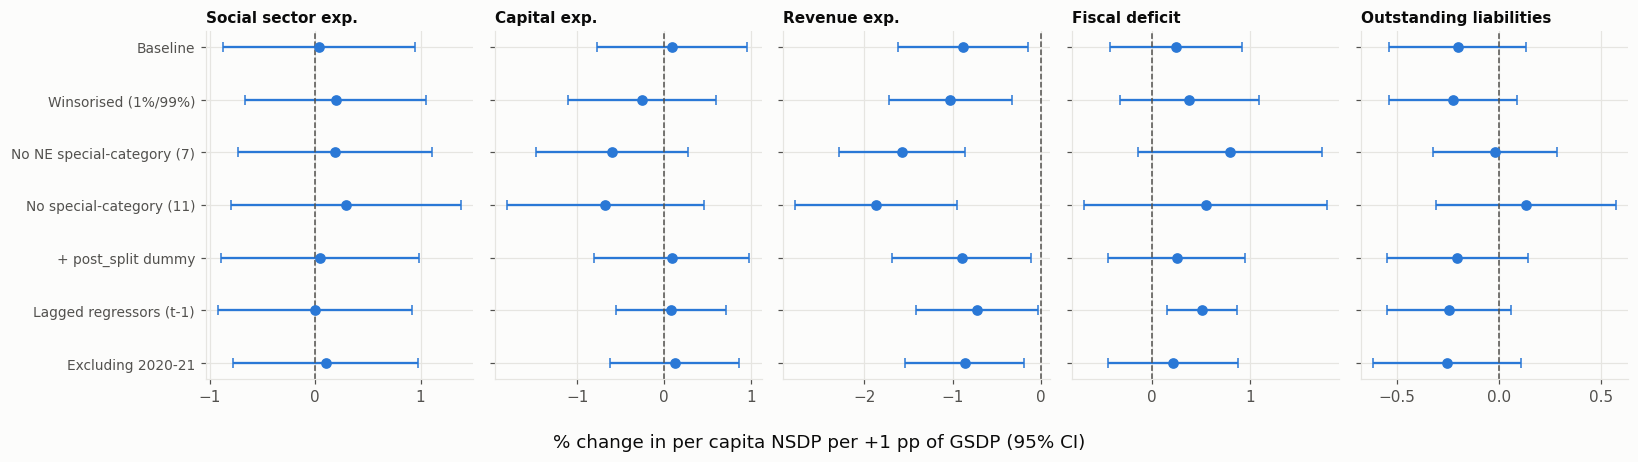

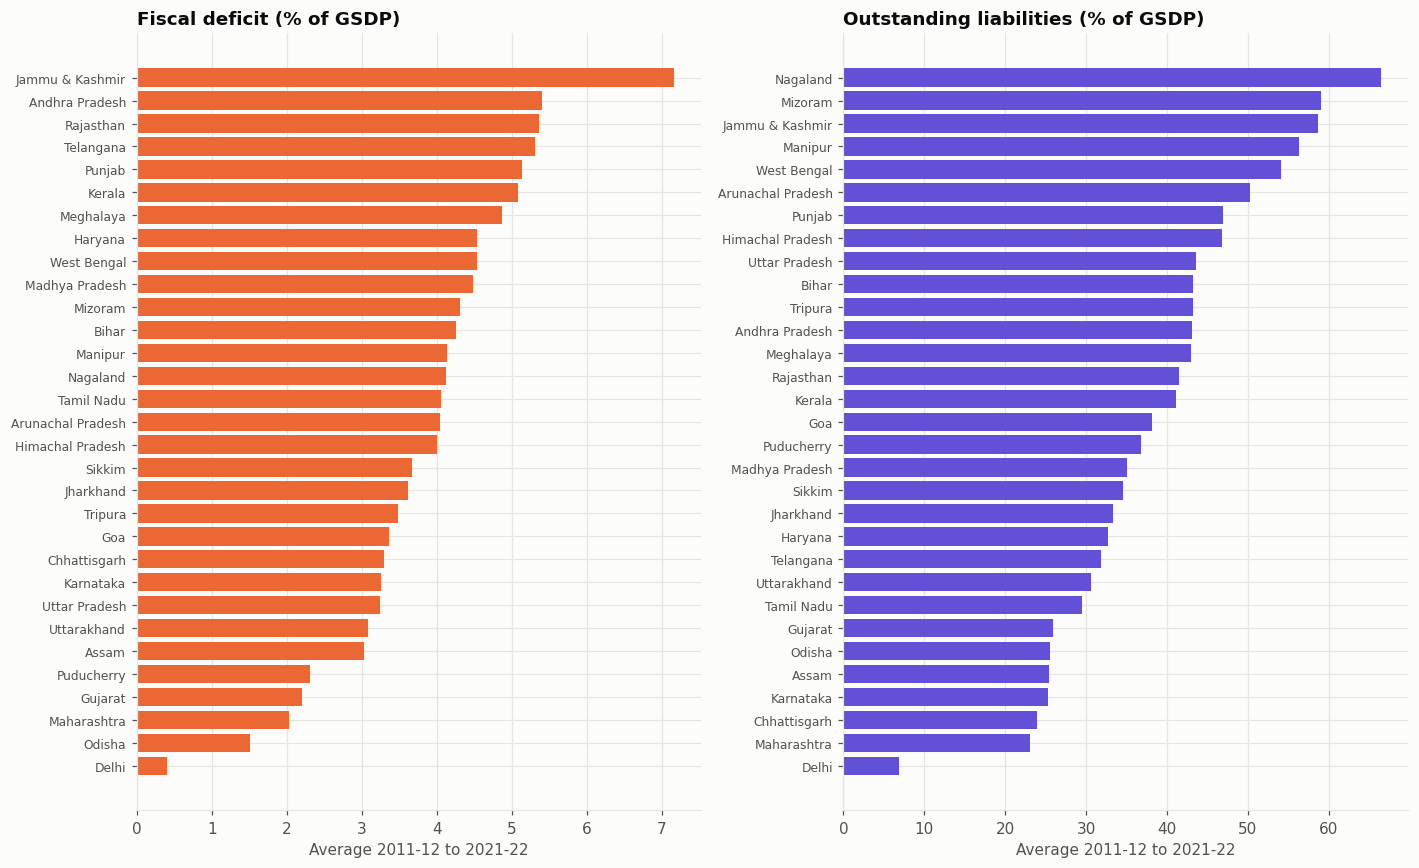

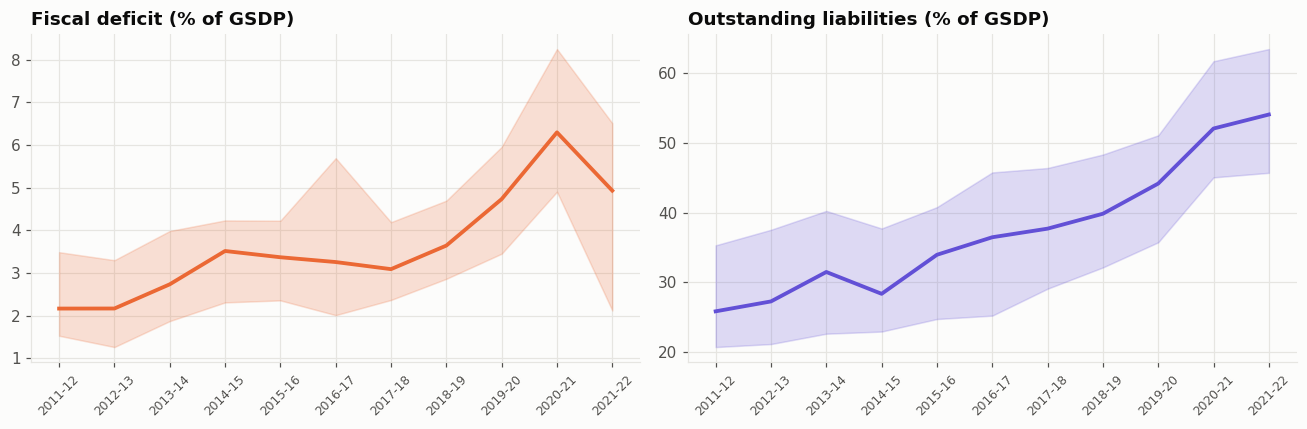

In [79]:
from scipy import stats as _st
MAIN, MODEL = "B (without ln GSDP)", "fe"        # main spec and model for the plots
o = res[MAIN]; X = o["X"]; G = o[MODEL]["G"]
tcrit = _st.t.ppf(0.975, G - 1)

# ---- 1. Coefficient plot: effect of +1 percentage point of GSDP on per capita NSDP (%), with 95% CI ----
t = o[MODEL]["table"].loc[X]
est, ci = t["coef"], t["se"] * tcrit        # coef is log-points per 1.00 (=100 pp) => per 1 pp it is coef/100 log pts = coef %
fig, ax = plt.subplots(figsize=(8, 4.2))
ypos = np.arange(len(X))[::-1]
ax.errorbar(est, ypos, xerr=ci, fmt="o", color="#2a78d6", ecolor="#2a78d6", capsize=4, lw=2)
ax.axvline(0, color="#52514e", lw=1, ls="--")
ax.set_yticks(ypos); ax.set_yticklabels([NICE[v] for v in X])
ax.set_xlabel("% change in per capita NSDP for +1 percentage point of GSDP (95% CI)")
ax.set_title(f"Fixed-effects estimates, spec {MAIN[0]}", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("fig_coef_plot.png", dpi=200); plt.show()

# ---- 2. Robustness plot: each coefficient across the six checks ----
rb = rob_fe[MAIN]
order = list(variants(df, X).keys())
fig, axes = plt.subplots(1, len(X), figsize=(3*len(X), 4.2), sharey=True)
for ax, v in zip(axes, X):
    d = rb[rb["var"] == v].set_index("variant").reindex(order)
    y = np.arange(len(order))[::-1]
    ax.errorbar(d["coef"], y, xerr=d["se"]*tcrit, fmt="o", color="#2a78d6", capsize=3, lw=1.5)
    ax.axvline(0, color="#52514e", lw=1, ls="--"); ax.set_title(NICE[v], fontsize=10)
axes[0].set_yticks(np.arange(len(order))[::-1]); axes[0].set_yticklabels(order, fontsize=9)
fig.supxlabel("% change in per capita NSDP per +1 pp of GSDP (95% CI)")
plt.tight_layout(); plt.savefig("fig_robustness_plot.png", dpi=200); plt.show()

# ---- 3. Fiscal deficit and liabilities across states (state averages, ranked) ----
fig, axes = plt.subplots(1, 2, figsize=(13, 8))
for ax, v, col, ttl in [(axes[0], "fd", "#eb6834", "Fiscal deficit (% of GSDP)"),
                        (axes[1], "liab", "#6250d6", "Outstanding liabilities (% of GSDP)")]:
    s = (df.groupby("State")[v].mean() * 100).sort_values()
    ax.barh(s.index, s.values, color=col); ax.set_title(ttl, loc="left", fontweight="bold")
    ax.set_xlabel("Average 2011-12 to 2021-22"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.savefig("fig_fd_liab_states.png", dpi=200); plt.show()

# ---- 4. Fiscal deficit and liabilities over time (median and middle 50% of states) ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v, col, ttl in [(axes[0], "fd", "#eb6834", "Fiscal deficit (% of GSDP)"),
                        (axes[1], "liab", "#6250d6", "Outstanding liabilities (% of GSDP)")]:
    g_ = df.groupby("Year")[v]
    med, q1, q3 = g_.median()*100, g_.quantile(.25)*100, g_.quantile(.75)*100
    ax.fill_between(range(len(med)), q1, q3, color=col, alpha=0.2); ax.plot(range(len(med)), med, color=col, lw=2.5)
    ax.set_xticks(range(len(med))); ax.set_xticklabels(med.index, rotation=45, fontsize=8); ax.set_title(ttl, loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("fig_fd_liab_trend.png", dpi=200); plt.show()

# ---- 5. Animated bar races (needs the animated-EDA cell that defines bar_race() to have been run) ----
ORANGE, VIOLET = "#eb6834", "#6250d6"
fig3c = bar_race("fd",   "fiscal deficit",          ORANGE); fig3c.show(); fig3c.write_html("anim_3_race_fiscal_deficit.html", auto_play=False)
fig3d = bar_race("liab", "outstanding liabilities", VIOLET); fig3d.show(); fig3d.write_html("anim_3_race_liabilities.html", auto_play=False)

In [80]:
import glob, zipfile
from google.colab import files

patterns = ["fig_*.png", "anim_*.html", "Tasks_3_to_5_Results.xlsx", "Task6_Tables.xlsx", "States_Data_Cleaned.xlsx"]
found = sorted({f for p in patterns for f in glob.glob(p)})
print("Packing", len(found), "files:"); [print("  ", f) for f in found]

with zipfile.ZipFile("Project_Outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in found: z.write(f)
files.download("Project_Outputs.zip")


Packing 14 files:
   States_Data_Cleaned.xlsx
   Task6_Tables.xlsx
   Tasks_3_to_5_Results.xlsx
   anim_1_trend.html
   anim_2_bubble_capital.html
   anim_2_bubble_social.html
   anim_3_race_capital.html
   anim_3_race_fiscal_deficit.html
   anim_3_race_liabilities.html
   anim_3_race_social.html
   fig_coef_plot.png
   fig_fd_liab_states.png
   fig_fd_liab_trend.png
   fig_robustness_plot.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>